# RMSD distribution of the training data and the effect of the RMSD cutoff

How much data does `filter_rmsd_max_value` remove at 10 Å vs 20 Å? The filter keeps complexes with `predicted_rmsd ≤ cutoff`. It is applied to **both** datasets **before** the split, so it also changes the test sets.

- **Activity data** (Kinodata-3D, `kinodata_docked_v2.pt`): `predicted_rmsd` is the RMSD *predicted* by the Kinodata-3D docking pipeline for the kept pose. Processing already keeps only the pose with the lowest predicted RMSD per (ligand, kinase, activity type).
- **Pose data** (POSIT cross-docking, `posit_combined.pt`): `predicted_rmsd` holds the *true* RMSD to the crystal pose (same field name).

Pose-quality classes follow the code: q = 1/(1+exp(0.9·(RMSD−4.5))). "Good" q ≥ 0.8 ↔ RMSD ≤ 2.96 Å; "bad" q ≤ 0.2 ↔ RMSD ≥ 6.04 Å; "medium" in between.

The filter compares with `<=`, so complexes **without an RMSD (NaN) are dropped by any cutoff**; they are counted separately below.

The first run reads the unfiltered processed datasets (about 40 GB RAM, a few minutes): **use a compute node**, not the login node. The per-complex table is then cached in `analysis/output/` and later runs only read the cache.

In [1]:
from pathlib import Path

# repo root = first parent folder that contains the kinodata package
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
OUTPUT = REPO / "analysis" / "output"
OUTPUT.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = REPO / "data" / "processed"
CUTOFFS = [10, 20]
Q_GOOD, Q_BAD = 0.8, 0.2
RMSD_GOOD = 4.5 - np.log(Q_GOOD / (1 - Q_GOOD)) / 0.9   # 2.96 A
RMSD_BAD = 4.5 + np.log((1 - Q_BAD) / Q_BAD) / 0.9      # 6.04 A
SCAFFOLD_CAP = 3000  # pose samples per scaffold in the scaffold split (hard-coded in grouped_split.py)
import sys
sys.path.insert(0, str(REPO / "analysis"))
from plot_style import apply_style, COLORS
apply_style()
print(f"good <= {RMSD_GOOD:.2f} A, bad >= {RMSD_BAD:.2f} A")

good <= 2.96 A, bad >= 6.04 A


In [2]:
def per_complex_table(pt_file, cache, keys):
    """predicted_rmsd and metadata of every complex in an unfiltered processed dataset (cached as csv.gz)."""
    if cache.exists():
        return pd.read_csv(cache)
    import torch
    data, _ = torch.load(pt_file)
    store = data._global_store
    cols = {}
    for k in keys:
        if k in store:
            v = store[k]
            cols[k] = v.numpy().ravel() if hasattr(v, "numpy") else list(v)
    df = pd.DataFrame(cols)
    del data
    df.to_csv(cache, index=False)
    return df


activity = per_complex_table(PROCESSED / "kinodata" / "kinodata_docked_v2.pt", OUTPUT / "rmsd_activity.csv.gz",
                             ["predicted_rmsd", "y", "activity_type", "scaffold", "pocket_sequence", "smiles", "ident"])
pose = per_complex_table(PROCESSED / "davidsdocked" / "posit_combined.pt", OUTPUT / "rmsd_pose.csv.gz",
                         ["predicted_rmsd", "scaffold", "pocket_sequence", "smiles", "docking_score", "ident"])
print(f"activity: {len(activity):,} complexes, columns {list(activity.columns)}")
print(f"pose:     {len(pose):,} poses, columns {list(pose.columns)}")

activity: 119,522 complexes, columns ['predicted_rmsd', 'y', 'activity_type', 'scaffold', 'pocket_sequence', 'smiles', 'ident']
pose:     80,155 poses, columns ['predicted_rmsd', 'scaffold', 'pocket_sequence', 'smiles', 'docking_score', 'ident']


## How much each cutoff removes

In [3]:
def cutoff_summary(df, name):
    r = df["predicted_rmsd"]
    rows = [{"dataset": name, "cutoff": "none", "kept": len(df), "removed": 0, "removed %": 0.0,
             "of which no RMSD (NaN)": 0}]
    for c in CUTOFFS:
        kept = int((r <= c).sum())
        rows.append({"dataset": name, "cutoff": f"<= {c} A", "kept": kept, "removed": len(df) - kept,
                     "removed %": round(100 * (len(df) - kept) / len(df), 2),
                     "of which no RMSD (NaN)": int(r.isna().sum())})
    return rows


summary = pd.DataFrame(cutoff_summary(activity, "activity (predicted RMSD)") + cutoff_summary(pose, "pose (true RMSD)"))
summary

,dataset,cutoff,kept,removed,removed %,of which no RMSD (NaN)
0,activity (predicted RMSD),none,119522,0,0.00,0
1,activity (predicted RMSD),<= 10 A,119421,101,0.08,0
2,activity (predicted RMSD),<= 20 A,119522,0,0.00,0
3,pose (true RMSD),none,80155,0,0.00,0
4,pose (true RMSD),<= 10 A,67976,12179,15.19,1392
5,pose (true RMSD),<= 20 A,75216,4939,6.16,1392


In [4]:
for name, df in [("activity", activity), ("pose", pose)]:
    r = df["predicted_rmsd"]
    print(f"{name:9s} RMSD min {r.min():.2f}, median {r.median():.2f}, 90th pct {r.quantile(0.9):.2f}, max {r.max():.2f} A; "
          f"between 10 and 20 A: {int(((r > 10) & (r <= 20)).sum()):,}; above 20 A: {int((r > 20).sum()):,}; "
          f"no RMSD (NaN): {int(r.isna().sum()):,}")

activity  RMSD min -0.94, median 4.14, 90th pct 6.41, max 16.03 A; between 10 and 20 A: 101; above 20 A: 0; no RMSD (NaN): 0
pose      RMSD min 0.08, median 4.36, 90th pct 11.43, max 171.37 A; between 10 and 20 A: 7,240; above 20 A: 3,547; no RMSD (NaN): 1,392


## Pose-quality classes removed by each cutoff

Everything above 10 Å is a "bad" pose (≥ 6.04 Å), so the cutoff removes bad poses only (plus the poses without an RMSD, which every cutoff drops). This matters for the "no pose left behind" framing (R2.1, R2.4).

In [5]:
def quality_class(r):
    return np.select([np.isnan(r), r <= RMSD_GOOD, r >= RMSD_BAD], ["no RMSD", "good", "bad"], "medium")


rows = []
for name, df in [("activity", activity), ("pose", pose)]:
    cls = pd.Series(quality_class(df["predicted_rmsd"].to_numpy()), index=df.index)
    for c in [None] + CUTOFFS:
        keep = np.ones(len(df), bool) if c is None else (df["predicted_rmsd"] <= c).to_numpy()
        counts = cls[keep].value_counts()
        rows.append({"dataset": name, "cutoff": "none" if c is None else f"<= {c} A",
                     **{k: int(counts.get(k, 0)) for k in ["good", "medium", "bad", "no RMSD"]},
                     "bad % (of those with RMSD)": round(100 * counts.get("bad", 0) / (keep.sum() - counts.get("no RMSD", 0)), 1)})
classes = pd.DataFrame(rows)
classes

,dataset,cutoff,good,medium,bad,no RMSD,bad % (of those with RMSD)
0,activity,none,47139,48155,24228,0,20.3
1,activity,<= 10 A,47139,48155,24127,0,20.2
2,activity,<= 20 A,47139,48155,24228,0,20.3
3,pose,none,30985,18553,29225,1392,37.1
4,pose,<= 10 A,30985,18553,18438,0,27.1
5,pose,<= 20 A,30985,18553,25678,0,34.1


## Distributions

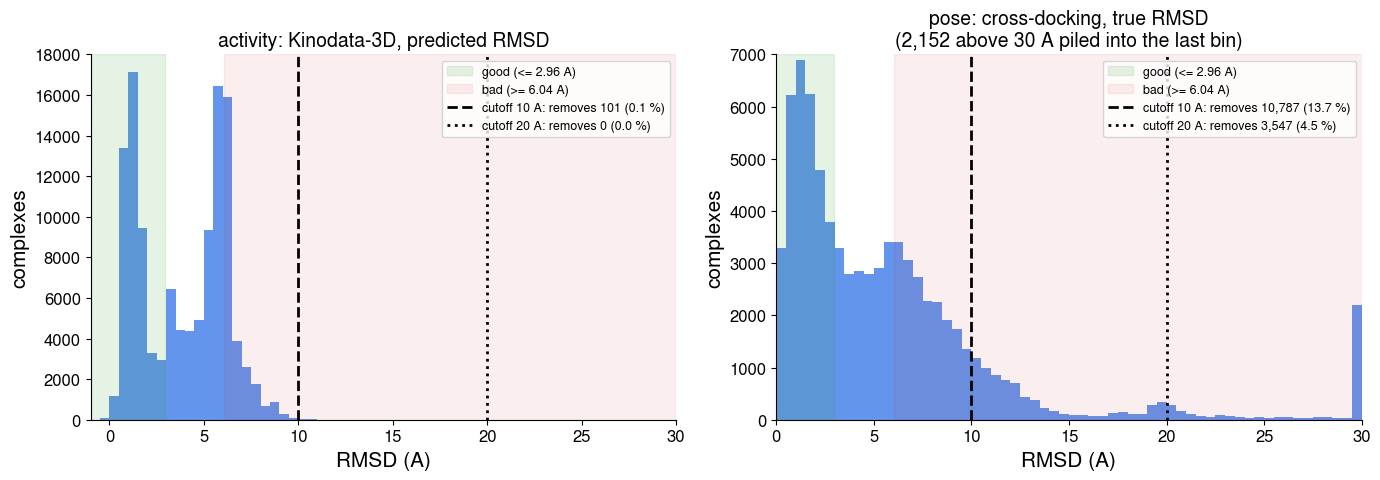

In [6]:
X_MAX = 30  # a few poses go up to ~170 A; they are counted in the title, not drawn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, df) in zip(axes, [("activity: Kinodata-3D, predicted RMSD", activity), ("pose: cross-docking, true RMSD", pose)]):
    r = df["predicted_rmsd"].dropna()
    ax.hist(r.clip(upper=X_MAX), bins=np.arange(np.floor(r.min()), X_MAX + 0.5, 0.5), color=COLORS["hist"])
    ax.axvspan(np.floor(r.min()), RMSD_GOOD, color=COLORS["good"], alpha=0.12, label=f"good (<= {RMSD_GOOD:.2f} A)")
    ax.axvspan(RMSD_BAD, X_MAX, color=COLORS["bad"], alpha=0.08, label=f"bad (>= {RMSD_BAD:.2f} A)")
    for c, ls in zip(CUTOFFS, ["--", ":"]):
        ax.axvline(c, color="k", ls=ls, label=f"cutoff {c} A: removes {int((r > c).sum()):,} ({100 * (r > c).mean():.1f} %)")
    n_out = int((r > X_MAX).sum())
    ax.set(title=name + (f"\n({n_out:,} above {X_MAX} A piled into the last bin)" if n_out else ""),
           xlabel="RMSD (A)", ylabel="complexes", xlim=(np.floor(r.min()), X_MAX))
    ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT / "rmsd_distribution.png")

## The sigmoid transformation RMSD → pose quality q, and the activity-loss weight

- Pose-quality target (`RegressionModel.rmsd_to_prob_transform`): q = 1 / (1 + exp(0.9 · (RMSD − 4.5))).
- Activity-loss weight: w = ε + (1 − ε) · q̂, with ε = 0.10 (reference configuration). It never drops below ε (dotted line), so even the worst poses keep 10 % of the weight of a perfect pose.
- During training q̂ is the model's *predicted* pose quality (detached). The weight curve below is the weight a complex would get if the pose head predicted its RMSD exactly.
- In the pose loss, poses with q ≤ 0.2 get weight 10 and poses with q ≥ 0.8 get weight 7.

Right panel: the q targets of the pose data. Everything above about 8 Å is squeezed to q ≈ 0, so the poses removed by the 10 Å cutoff have practically the same target as the 8–10 Å poses that are kept.

,RMSD (A),q,activity weight (eps 0.1),pose-loss class weight
0,1.00,0.959,0.963,7
1,2.00,0.905,0.914,7
2,2.50,0.858,0.872,7
3,2.96,0.800,0.820,7
4,4.50,0.500,0.550,1
5,6.04,0.200,0.280,1
6,8.00,0.041,0.137,10
7,10.00,0.007,0.106,10
8,20.00,0.000,0.100,10


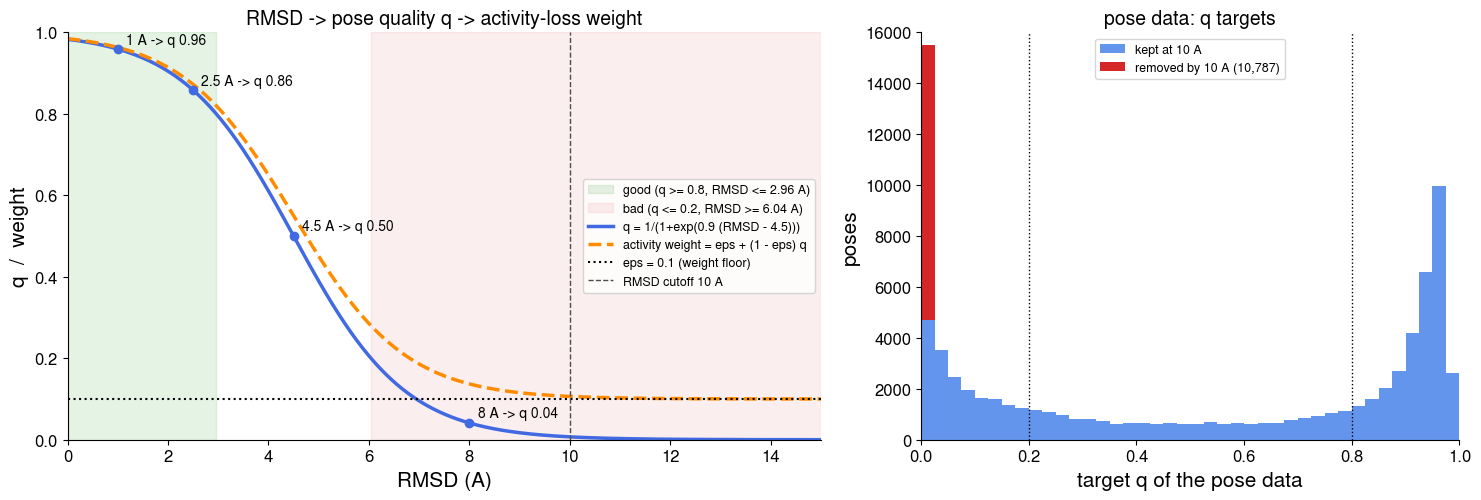

In [7]:
SIGMOID_K, SIGMOID_X0 = 0.9, 4.5   # as in RegressionModel.rmsd_to_prob_transform
EPS = 0.10                         # activity-loss weight floor (reference configuration)


def rmsd_to_q(r):
    return 1 / (1 + np.exp(SIGMOID_K * (np.asarray(r, float) - SIGMOID_X0)))


def activity_weight(r, eps=EPS):
    return eps + (1 - eps) * rmsd_to_q(r)


MARKED = [1, 2, 2.5, RMSD_GOOD, 4.5, RMSD_BAD, 8, 10, 20]
table = pd.DataFrame({"RMSD (A)": np.round(MARKED, 2), "q": rmsd_to_q(MARKED).round(3),
                      f"activity weight (eps {EPS})": activity_weight(MARKED).round(3),
                      "pose-loss class weight": np.select([rmsd_to_q(MARKED) <= Q_BAD, rmsd_to_q(MARKED) >= Q_GOOD], [10, 7], 1)})
display(table)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
x = np.linspace(0, 15, 600)
ax.axvspan(0, RMSD_GOOD, color=COLORS["good"], alpha=0.12, label=f"good (q >= {Q_GOOD}, RMSD <= {RMSD_GOOD:.2f} A)")
ax.axvspan(RMSD_BAD, 15, color=COLORS["bad"], alpha=0.08, label=f"bad (q <= {Q_BAD}, RMSD >= {RMSD_BAD:.2f} A)")
ax.plot(x, rmsd_to_q(x), color=COLORS["pose_aware"], lw=2.5, label="q = 1/(1+exp(0.9 (RMSD - 4.5)))")
ax.plot(x, activity_weight(x), color="darkorange", lw=2.5, ls="--", label=f"activity weight = eps + (1 - eps) q")
ax.axhline(EPS, color="k", ls=":", lw=1.5, label=f"eps = {EPS} (weight floor)")
ax.axvline(10, color="0.3", ls="--", lw=1, label="RMSD cutoff 10 A")
for r in [1, 2.5, 4.5, 8]:
    ax.plot(r, rmsd_to_q(r), "o", color=COLORS["pose_aware"], ms=6)
    ax.annotate(f"{r:g} A -> q {rmsd_to_q(r):.2f}", (r, rmsd_to_q(r)), xytext=(6, 4), textcoords="offset points", fontsize=10)
ax.set(xlabel="RMSD (A)", ylabel="q  /  weight", xlim=(0, 15), ylim=(0, 1),
       title="RMSD -> pose quality q -> activity-loss weight")
ax.legend(fontsize=9, loc="center right")

q_pose = rmsd_to_q(pose["predicted_rmsd"].dropna())
r_pose = pose["predicted_rmsd"].dropna()
bins = np.linspace(0, 1, 41)
ax2.hist([q_pose[r_pose <= 10], q_pose[r_pose > 10]], bins=bins, stacked=True,
         color=[COLORS["hist"], COLORS["bad"]], label=["kept at 10 A", f"removed by 10 A ({int((r_pose > 10).sum()):,})"])
ax2.axvline(Q_BAD, color="k", ls=":", lw=1)
ax2.axvline(Q_GOOD, color="k", ls=":", lw=1)
ax2.set(xlabel="target q of the pose data", ylabel="poses", title="pose data: q targets", xlim=(0, 1))
ax2.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT / "sigmoid_transformation.png")

## Choice of the sigmoid parameters (R1.2)

q = 1 / (1 + exp(k · (RMSD − x₀))):
- **x₀** is the midpoint, the RMSD where q = 0.5.
- **k** sets the steepness. q falls from 0.8 to 0.2 over 2·ln(4)/k Å (3.1 Å for k = 0.9: from 2.96 to 6.04 Å).

The question is what the training targets look like for the pose data under different (k, x₀):
- **Too flat (small k):** the targets bunch up in the middle and good and bad poses are hard to tell apart.
- **Too steep (large k):** the target becomes a binary good/bad label with no middle values, so nothing is learned about "medium" poses.
- **Midpoint shifted:** almost all poses end up in one class.

The reference (0.9, 4.5) spreads the targets over the whole range with both ends populated.

**How to use:** edit `SIGMOID_PARAMS` (and `POSE_CUTOFF`) in the next cell and re-run the cells of this section. Only the pose data is needed (no reload). The first entry is drawn as the reference.

The table reports, per parameter set:
- the q 0.8 → 0.2 window in Å;
- the share of good (q ≥ 0.8), medium and bad (q ≤ 0.2) poses, which with the pose-loss weights 10 / 1 / 7 sets the class balance;
- the share of poses with q in the middle third (1/3–2/3);
- a flatness score: normalized entropy of the q histogram, 1 = perfectly uniform, near 0 = everything in one bin.

This shows the targets only. Whether the *results* are robust to the parameters (the second half of R1.2) needs retraining with other values.

In [8]:
# ---- edit me ----------------------------------------------------------------------------------
SIGMOID_PARAMS = [      # (k, x0); the first one is the reference used in the paper
    (0.9, 4.5),
    (0.7, 5.4), (1.25, 4.5), (1.25, 6.0), (1.3, 5.0),   # earlier candidates (runs/archive_iris_2025/misc/transformation_*.png)
    (0.3, 4.5),         # too flat
    (3.0, 4.5),         # too steep: binary, no middle values
    (0.9, 2.0),         # midpoint too low: almost every pose "bad"
    (0.9, 8.0),         # midpoint too high: almost every pose "good"
]
POSE_CUTOFF = 10        # RMSD filter on the pose data before transforming (None = all poses with an RMSD)
N_BINS = 40             # bins of the q histograms
# -------------------------------------------------------------------------------------------------

In [9]:
def sigmoid_q(r, k, x0):
    return 1 / (1 + np.exp(k * (np.asarray(r, float) - x0)))


r_pose = pose["predicted_rmsd"].dropna()
if POSE_CUTOFF is not None:
    r_pose = r_pose[r_pose <= POSE_CUTOFF]
print(f"{len(r_pose):,} poses (cutoff: {POSE_CUTOFF} A)")

rows = []
for k, x0 in SIGMOID_PARAMS:
    q = sigmoid_q(r_pose, k, x0)
    p = np.histogram(q, bins=N_BINS, range=(0, 1))[0] / len(q)
    p_nz = p[p > 0]
    rows.append({
        "k": k, "x0": x0,
        "q 0.8->0.2 window (A)": f"{x0 - np.log(4) / k:.2f}-{x0 + np.log(4) / k:.2f}",
        "good % (q>=0.8)": round(100 * np.mean(q >= Q_GOOD), 1),
        "medium %": round(100 * np.mean((q > Q_BAD) & (q < Q_GOOD)), 1),
        "bad % (q<=0.2)": round(100 * np.mean(q <= Q_BAD), 1),
        "middle third % (1/3<q<2/3)": round(100 * np.mean((q > 1 / 3) & (q < 2 / 3)), 1),
        "flatness (norm. entropy)": round(float(-(p_nz * np.log(p_nz)).sum() / np.log(N_BINS)), 2),
    })
sigmoid_table = pd.DataFrame(rows)
sigmoid_table

67,976 poses (cutoff: 10 A)


,k,x0,q 0.8->0.2 window (A),good % (q>=0.8),medium %,bad % (q<=0.2),middle third % (1/3<q<2/3),flatness (norm. entropy)
0,0.90,4.5,2.96-6.04,45.6,27.3,27.1,12.6,0.90
1,0.70,5.4,3.42-7.38,50.1,35.0,14.9,18.0,0.88
2,1.25,4.5,3.39-5.61,49.8,18.7,31.5,9.1,0.78
3,1.25,6.0,4.89-7.11,62.3,20.5,17.1,11.1,0.69
4,1.30,5.0,3.93-6.07,54.4,18.7,26.8,9.0,0.74
5,0.30,4.5,-0.12-9.12,0.0,96.2,3.8,44.0,0.86
6,3.00,4.5,4.04-4.96,55.2,7.7,37.1,3.9,0.47
7,0.90,2.0,0.46-3.54,4.2,46.9,48.8,25.0,0.83
8,0.90,8.0,6.46-9.54,77.1,21.1,1.8,10.3,0.59


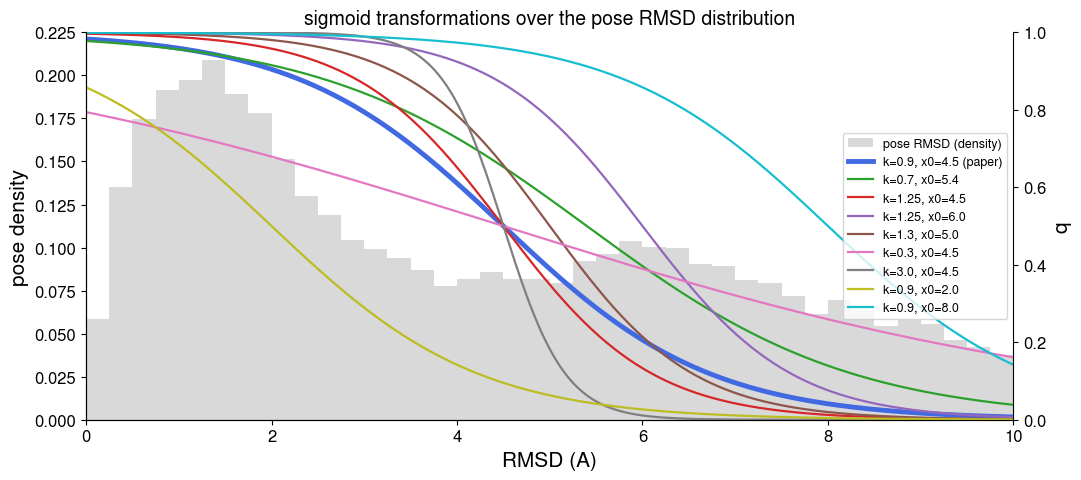

In [10]:
# where each transition falls relative to the RMSD distribution of the pose data
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(r_pose, bins=np.arange(0, (POSE_CUTOFF or 30) + 0.25, 0.25), color="0.85", density=True, label="pose RMSD (density)")
ax2 = ax.twinx()
ax2.spines["right"].set_visible(True)   # twin axis for q
x = np.linspace(0, POSE_CUTOFF or 30, 500)
for i, (k, x0) in enumerate(SIGMOID_PARAMS):
    ref = i == 0
    ax2.plot(x, sigmoid_q(x, k, x0), lw=3.5 if ref else 1.6, color=COLORS["pose_aware"] if ref else f"C{i + 1}",
             label=f"k={k}, x0={x0}" + (" (paper)" if ref else ""))
ax.set(xlabel="RMSD (A)", ylabel="pose density", xlim=(0, POSE_CUTOFF or 30))
ax2.set(ylabel="q", ylim=(0, 1))
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, fontsize=9, loc="center right")
ax.set_title("sigmoid transformations over the pose RMSD distribution")
fig.tight_layout()
fig.savefig(OUTPUT / "sigmoid_params_curves.png")

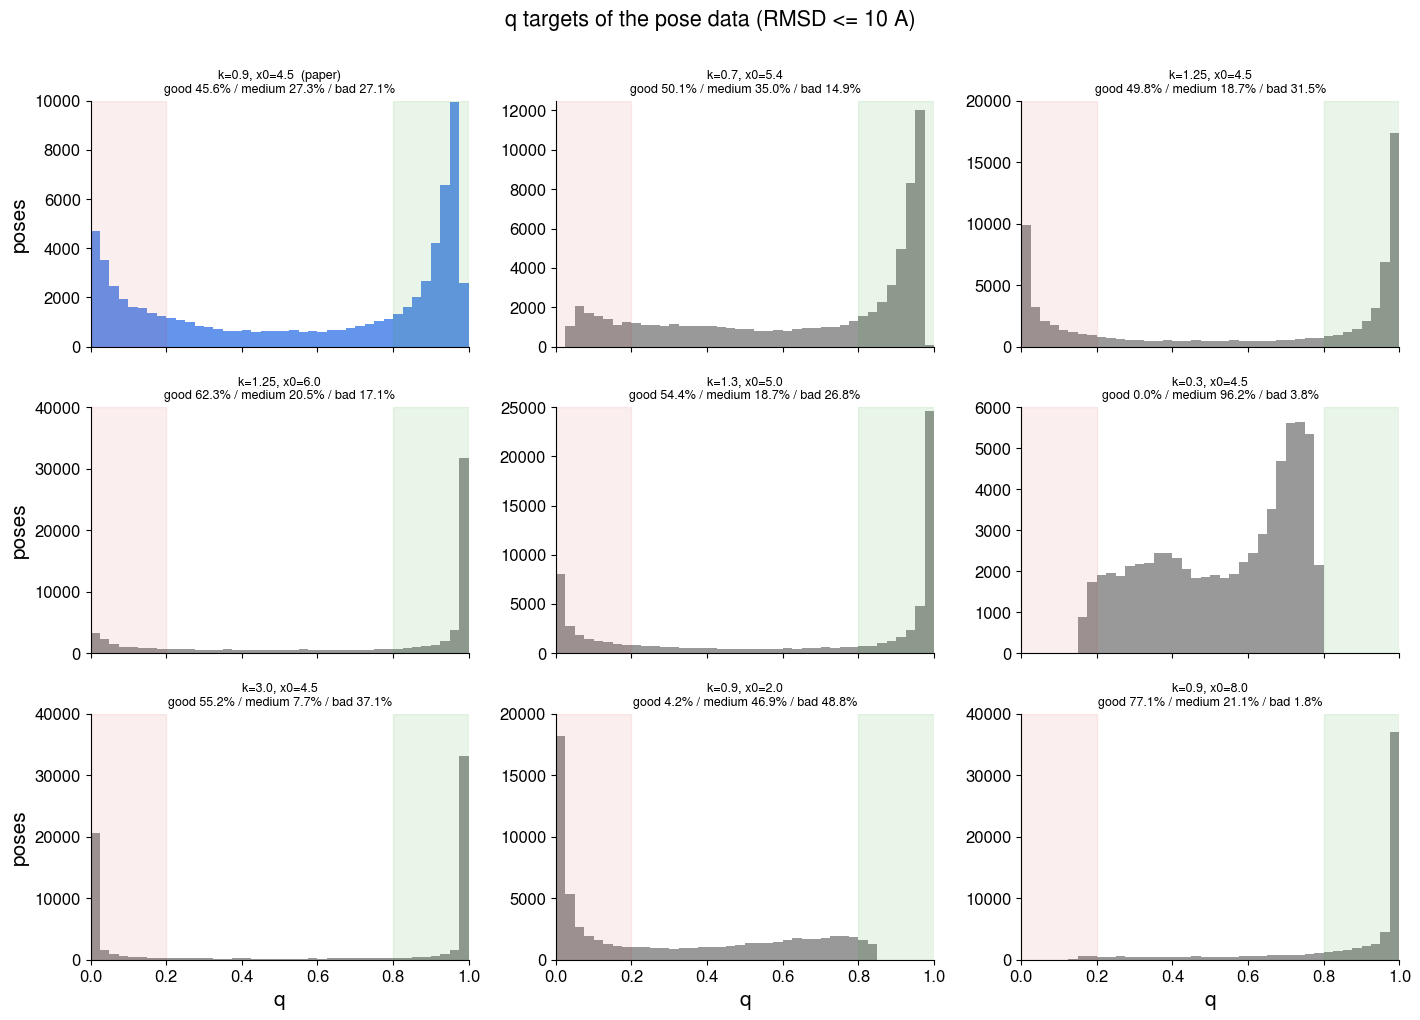

In [11]:
# histogram of the resulting q targets, one panel per parameter set
ncols = 3
nrows = int(np.ceil(len(SIGMOID_PARAMS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.8 * ncols, 3.4 * nrows), sharex=True, squeeze=False)
for ax, (k, x0), row in zip(axes.flat, SIGMOID_PARAMS, rows):
    q = sigmoid_q(r_pose, k, x0)
    ref = (k, x0) == SIGMOID_PARAMS[0]
    ax.hist(q, bins=N_BINS, range=(0, 1), color=COLORS["hist"] if ref else COLORS["neutral"])
    ax.axvspan(0, Q_BAD, color=COLORS["bad"], alpha=0.08)
    ax.axvspan(Q_GOOD, 1, color=COLORS["good"], alpha=0.10)
    ax.set_xlim(0, 1)
    ax.set_title(f"k={k}, x0={x0}" + ("  (paper)" if ref else "") +
                 f"\ngood {row['good % (q>=0.8)']}% / medium {row['medium %']}% / bad {row['bad % (q<=0.2)']}%", fontsize=9)
for ax in axes.flat[len(SIGMOID_PARAMS):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("q")
for ax in axes[:, 0]:
    ax.set_ylabel("poses")
fig.suptitle(f"q targets of the pose data (RMSD <= {POSE_CUTOFF} A)" if POSE_CUTOFF else "q targets of the pose data", y=1.0)
fig.tight_layout()
fig.savefig(OUTPUT / "sigmoid_params_q_hist.png")

## What the models actually train on in the scaffold split

The scaffold split caps the pose data at 3000 poses per scaffold. Here the cap is applied as a count, min(n, 3000) per scaffold. For 20 Å this should reproduce the 64,716 pose samples seen in the split logs (2026-10-16).

The table also shows how many scaffolds, pocket sequences (kinases) and ligands each cutoff removes completely.

In [12]:
rows = []
for name, df in [("activity", activity), ("pose", pose)]:
    for c in [None] + CUTOFFS:
        sub = df if c is None else df[df["predicted_rmsd"] <= c]
        row = {"dataset": name, "cutoff": "none" if c is None else f"<= {c} A", "complexes": len(sub),
               "scaffolds": sub["scaffold"].nunique(), "pockets": sub["pocket_sequence"].nunique()}
        if "smiles" in sub:
            row["ligands"] = sub["smiles"].nunique()
        if name == "pose":
            row["after 3000/scaffold cap"] = int(sub.groupby("scaffold").size().clip(upper=SCAFFOLD_CAP).sum())
        rows.append(row)
pd.DataFrame(rows)

,dataset,cutoff,complexes,scaffolds,pockets,ligands,after 3000/scaffold cap
0,activity,none,119522,16361,850,88434,NaN
1,activity,<= 10 A,119421,16348,850,88386,NaN
2,activity,<= 20 A,119522,16361,850,88434,NaN
3,pose,none,80155,1005,131,1843,68409.0
4,pose,<= 10 A,67976,980,131,1789,58934.0
5,pose,<= 20 A,75216,989,131,1806,64716.0


## Are the removed activity complexes different?

Compares the pIC50 (`y`, raw values before z-scoring) of activity complexes kept vs removed by the 10 Å cutoff. If they are similar, the cutoff does not shift the activity distribution.

In [13]:
if "y" in activity:
    r = activity["predicted_rmsd"]
    groups = {"<= 10 A": activity.loc[r <= 10, "y"], "10-20 A": activity.loc[(r > 10) & (r <= 20), "y"], "> 20 A": activity.loc[r > 20, "y"]}
    display(pd.DataFrame({k: v.describe().round(2) for k, v in groups.items()}).T)

,count,mean,std,min,25%,50%,75%,max
<= 10 A,119421.0,7.16,1.29,1.02,6.25,7.28,8.10,14.0
10-20 A,101.0,6.94,1.49,4.00,5.62,7.22,8.05,10.0
> 20 A,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
